# Trajectory inference benchmarking for synthetic data

Here, we compare the inferred cell fates for the 4 synthetic curated datasets (10 different versions of each dataset) from BEELINE ([Pratapa et al. (2020)](https://doi.org/10.1038/s41592-019-0690-6)), recovered with bowside, Palantir, or CellRank.
Since BEELINE is originally a benchmark for dynamic GRN inference rather than for trajectory inference, it does not have a proper ground truth for cell fates.
However, the pseudotime annotations in BEELINE are such that each cell only belongs to one trajectory.
Accordingly, we use this information as a ground truth for our benchmark, with the caveat that early, uncommited cells also only belong to one ground-truth trajectory.
As a random baseline for comparison, we assign each cell randomly to one of the ground truth fates.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    adjusted_mutual_info_score,
    adjusted_rand_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
)

In [2]:
OUTDIR = Path("../output/")
OUTDIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Load all results
dataset_names = ["GSD", "HSC", "mCAD", "VSC"]
n_runs = 10
fate_probabilities = {
    name: {
        "Palantir": [
            pd.read_parquet(
                OUTDIR / f"BEELINE_{name}/palantir/fate_probabilities_{i}.parquet"
            )
            for i in range(n_runs)
        ],
        "CellRank-Connectivity": [
            pd.read_parquet(
                OUTDIR
                / f"BEELINE_{name}/cellrank/fate_probabilities_connectivity_{i}.parquet"
            )
            for i in range(n_runs)
        ],
        "CellRank-Pseudotime": [
            pd.read_parquet(
                OUTDIR
                / f"BEELINE_{name}/cellrank/fate_probabilities_pseudotime_{i}.parquet"
            )
            for i in range(n_runs)
        ],
        "bowside": [
            pd.read_parquet(
                OUTDIR
                / f"BEELINE_{name}/bowside_optimized/model_{i}/fate_probabilities.parquet"
            )
            for i in range(n_runs)
        ],
    }
    for name in dataset_names
}

In [4]:
# Load the true pseudotimes and convert them into fate labels
pseudotimes = {
    name: [
        pd.read_csv(
            f"../data/BEELINE-data/inputs/Curated/{name}/{name}-2000-{i + 1}/PseudoTime.csv",
            index_col=0,
        )
        for i in range(n_runs)
    ]
    for name in dataset_names
}
true_fates = {
    name: [df.idxmax(axis=1).str.replace("PseudoTime", "").astype(int) for df in lst]  # type: ignore
    for name, lst in pseudotimes.items()
}

In [5]:
# Add a random baseline: shuffle the true fate labels (preserves the number and
# proportions of fates) and encode them as one-hot "fate probabilities"
rng = np.random.default_rng(42)
for name, fates in true_fates.items():
    random_probs = []
    for true in fates:
        shuffled = pd.Series(rng.permutation(true.to_numpy()), index=true.index)
        probs = pd.get_dummies(shuffled).astype(float)
        probs.columns = [
            f"fate_probability_{int(label) - 1}" for label in probs.columns
        ]
        random_probs.append(probs)
    fate_probabilities[name]["random"] = random_probs

In [6]:
# Turn fate probabilities into predicted fates
predicted_fates = {
    name: {
        method: [
            df.filter(regex="fate_probability", axis=1)
            .idxmax(axis=1)
            .str.replace("fate_probability_", "")  # type: ignore
            .astype(int)
            + 1
            for df in lst
        ]
        for method, lst in sub_dict.items()
    }
    for name, sub_dict in fate_probabilities.items()
}

In [7]:
def label_free_scores(pred: pd.Series, true: pd.Series) -> dict:
    pred = pred.loc[true.index]
    return {
        "AMI": adjusted_mutual_info_score(true, pred),
        "ARI": adjusted_rand_score(true, pred),
    }

In [ ]:
def match_fates(probs: pd.DataFrame, true: pd.Series) -> dict:
    """One-to-one mapping maximising mean probability."""
    probs = probs.filter(regex="fate_probability").loc[true.index]
    true_labels = np.sort(true.unique())
    M = np.stack([probs[true == t].mean(axis=0).to_numpy() for t in true_labels])
    rows, cols = linear_sum_assignment(M, maximize=True)
    return {probs.columns[c]: true_labels[r] for r, c in zip(rows, cols)}


def matched_scores(probs: pd.DataFrame, true: pd.Series) -> dict:
    probs = probs.filter(regex="fate_probability").loc[true.index]
    mapping = match_fates(probs, true)
    # Hard labels; cells assigned to an unmatched (surplus) fate count as wrong
    pred = probs.idxmax(axis=1).map(mapping).fillna(-1).astype(int)
    scores = {
        "balanced_accuracy": balanced_accuracy_score(true, pred),
        "F1": f1_score(true, pred, labels=np.sort(true.unique()), average="macro"),
    }
    # Per-true-fate one-vs-rest AUROC, macro-averaged (= multi_class="ovr", average="macro")
    labels = np.sort(true.unique())
    inv = {t: c for c, t in mapping.items()}
    matched = np.column_stack(
        [probs[inv[t]] if t in inv else np.zeros(len(true)) for t in labels]
    )
    onehot = pd.get_dummies(true).reindex(columns=labels).to_numpy()
    scores["mean_AUROC"] = roc_auc_score(
        onehot, matched, multi_class="ovr", average="macro"
    )

    return scores


In [9]:
result_rows = []
for name, sub_dict in fate_probabilities.items():
    for method, lst in sub_dict.items():
        for i, probs in enumerate(lst):
            true = true_fates[name][i]
            n_pred = probs.filter(regex="fate_probability").shape[1]
            if n_pred == 0:  # e.g. Palantir runs that found no terminal states
                continue
            result_rows.append(
                {
                    "dataset": name,
                    "method": method,
                    "run": i,
                    "n_fates": n_pred,
                    **label_free_scores(predicted_fates[name][method][i], true),
                    **matched_scores(probs, true),
                }
            )
results = pd.DataFrame(result_rows)

/Users/janschleicher/miniconda3/envs/bowside/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/janschleicher/miniconda3/envs/bowside/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/janschleicher/miniconda3/envs/bowside/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/janschleicher/miniconda3/envs/bowside/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/janschleicher/miniconda3/envs/bowside/lib/python3.12/site-packages/sklearn/metrics/_classification.py

In [13]:
display(
    results.groupby(["method", "dataset"])[
        ["AMI", "ARI", "balanced_accuracy", "F1", "mean_AUROC"]
    ].agg(["mean", "std"])
)

AMI                 ARI            \
                                   mean       std      mean       std   
method                dataset                                           
CellRank-Connectivity GSD      0.335370  0.048152  0.356073  0.050708   
                      HSC      0.699405  0.044098  0.741521  0.062507   
                      VSC      0.602452  0.075495  0.523582  0.156311   
                      mCAD     0.460810  0.057372  0.490771  0.110635   
CellRank-Pseudotime   GSD      0.471654  0.058401  0.567304  0.089691   
                      HSC      0.781616  0.037430  0.833068  0.054792   
                      VSC      0.596534  0.065256  0.505530  0.142585   
                      mCAD     0.482081  0.081203  0.491769  0.154681   
Palantir              GSD      0.466918  0.062592  0.491929  0.111701   
                      HSC      0.635918  0.097028  0.596062  0.186033   
                      VSC      0.665155  0.029102  0.602668  0.063446   
                      mCAD     0.481023  0.087320  0.471196  0.152924   
bowside               GSD      0.422664  0.050456  0.548193  0.060172   
                      HSC      0.553900  0.105929  0.629146  0.092837   
                      VSC      0.528246  0.068540  0.575636  0.085091   
                      mCAD     0.486899  0.082973  0.585468  0.081575   
random                GSD     -0.000182  0.000271  0.000641  0.004283   
                      HSC     -0.000188  0.001016  0.002617  0.004585   
                      VSC      0.000493  0.000784 -0.000081  0.001141   
                      mCAD    -0.000074  0.000358 -0.001841  0.004241   

                              balanced_accuracy                  F1            \
                                           mean       std      mean       std   
method                dataset                                                   
CellRank-Connectivity GSD              0.704090  0.045187  0.770496  0.033682   
                      HSC              0.711309  0.078006  0.672448  0.115202   
                      VSC              0.597695  0.116604  0.562662  0.141433   
                      mCAD             0.782932  0.048754  0.839950  0.032591   
CellRank-Pseudotime   GSD              0.830314  0.062323  0.852238  0.047747   
                      HSC              0.862458  0.057480  0.865300  0.083602   
                      VSC              0.617222  0.138239  0.564033  0.169579   
                      mCAD             0.789242  0.088437  0.833870  0.069360   
Palantir              GSD              0.833099  0.029325  0.832841  0.029019   
                      HSC              0.747612  0.125537  0.693478  0.177643   
                      VSC              0.813486  0.033646  0.826495  0.032414   
                      mCAD             0.848749  0.032289  0.830312  0.049122   
bowside               GSD              0.847587  0.011662  0.853830  0.015756   
                      HSC              0.649861  0.113131  0.589852  0.142809   
                      VSC              0.650504  0.037711  0.595292  0.061986   
                      mCAD             0.880351  0.016615  0.872357  0.030258   
random                GSD              0.506801  0.005080  0.486912  0.045619   
                      HSC              0.269450  0.008309  0.226466  0.025563   
                      VSC              0.226311  0.005717  0.155277  0.024680   
                      mCAD             0.508372  0.005885  0.475683  0.042433   

                              mean_AUROC            
                                    mean       std  
method                dataset                       
CellRank-Connectivity GSD       0.917817  0.009400  
                      HSC       0.888275  0.055237  
                      VSC       0.817406  0.069628  
                      mCAD      0.962533  0.009010  
CellRank-Pseudotime   GSD       0.947580  0.012235  
                      HSC       0.979649  0.041146  
               

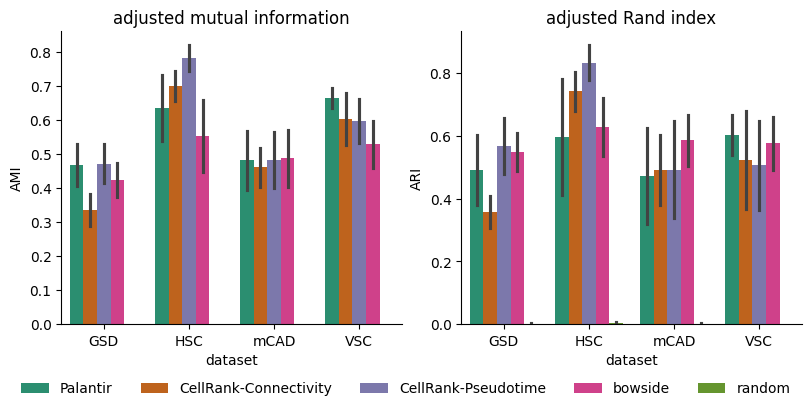

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
sns.barplot(
    results,
    x="dataset",
    y="AMI",
    hue="method",
    errorbar="sd",
    palette="Dark2",
    ax=axs[0],
)
axs[0].set_title("adjusted mutual information")
sns.barplot(
    results,
    x="dataset",
    y="ARI",
    hue="method",
    errorbar="sd",
    palette="Dark2",
    ax=axs[1],
)
axs[1].set_title("adjusted Rand index")

handles, labels = axs[0].get_legend_handles_labels()
for ax in axs.flat:
    ax.set_xlabel("dataset")
    ax.get_legend().remove()
    ax.set_ylim(0, None)
fig.legend(handles, labels, loc="outside lower center", ncol=5, frameon=False)
sns.despine(fig)

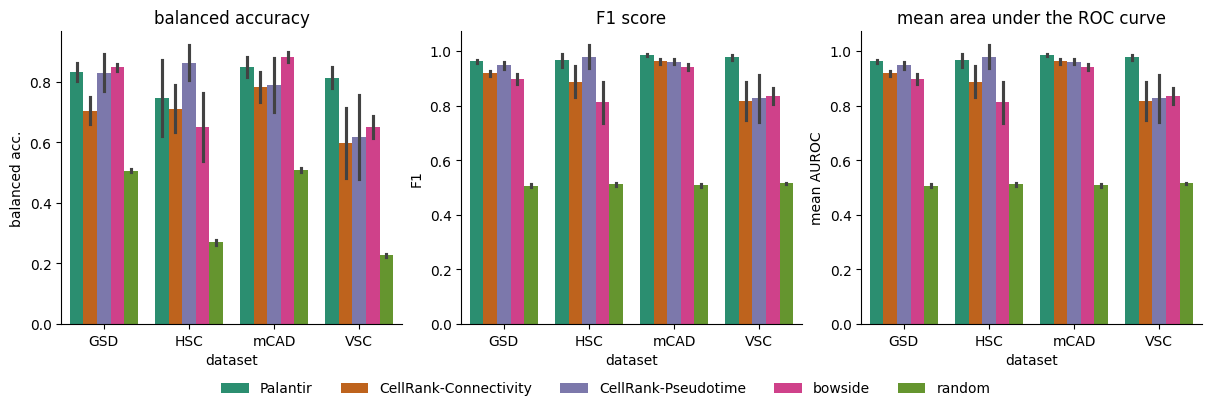

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
sns.barplot(
    results,
    x="dataset",
    y="balanced_accuracy",
    hue="method",
    errorbar="sd",
    palette="Dark2",
    ax=axs[0],
)
axs[0].set_title("balanced accuracy")
axs[0].set_ylabel("balanced acc.")
sns.barplot(
    results,
    x="dataset",
    y="mean_AUROC",
    hue="method",
    errorbar="sd",
    palette="Dark2",
    ax=axs[1],
)
axs[1].set_title("F1 score")
axs[1].set_ylabel("F1")
sns.barplot(
    results,
    x="dataset",
    y="mean_AUROC",
    hue="method",
    errorbar="sd",
    palette="Dark2",
    ax=axs[2],
)
axs[2].set_title("mean area under the ROC curve")
axs[2].set_ylabel("mean AUROC")

handles, labels = axs[0].get_legend_handles_labels()
for ax in axs.flat:
    ax.set_xlabel("dataset")
    ax.get_legend().remove()
    ax.set_ylim(0, None)
fig.legend(handles, labels, loc="outside lower center", ncol=5, frameon=False)
sns.despine(fig)

In [18]:
results.to_parquet(OUTDIR / "BEELINE_trajectory_benchmark_results.parquet")